### ODR

this is the lens experiment, bc errors on x and y are nearly the same, so errors on x are not trascurable  


REMEMBER function is written invertes, first want params, then x  

In [1]:
import numpy as np
from scipy import odr

In [2]:
from scipy.optimize import curve_fit

In [3]:
x  = [8.24734, 5.97840, 4.83381, 4.24801, 3.60843, 3.22218, 2.90327, 2.67710, 2.41840, 2.21594]
dx = [0.34009, 0.17871, 0.11683, 0.09023, 0.06510, 0.05191, 0.04214, 0.03583, 0.02924, 0.02455]
y  = [2.31995, 3.92591, 5.10248, 5.64159, 6.19471, 6.77478, 7.22337, 7.09194, 7.71537, 8.13141]
dy = [0.02691, 0.07706, 0.13018, 0.15914, 0.19187, 0.22949, 0.26089, 0.25148, 0.29763, 0.33060]

In [4]:
def fit_model(pars, x):
    # Note the independent variable is the last argument.
    return pars[0] * x + pars[1]


# the function is bc i'm doing a linear fit  
# it's like defining a function for a normal fit, but x must be the last in the call  
# can ask the params one at a time too  

In [5]:
# here, put stuff will need for the model
x=x
y=y
dx=dx
dy=dy
fit_model=fit_model

In [6]:
# Run the actual ODR.

model = odr.Model(fit_model)
data = odr.RealData(x, y, sx=dx, sy=dy)
alg = odr.ODR(data, model, beta0=(1.0, 1.0))
out = alg.run()

m_hat, q_hat = out.beta
sigma_m, sigma_q = np.sqrt(out.cov_beta.diagonal())
chisq = out.sum_square

In [7]:
# Print the fit output.

print(f'm = {m_hat:.3f} +/- {sigma_m:.3f}')
print(f'q = {q_hat:.3f} +/- {sigma_q:.3f}')
print(f'Chisquare = {chisq:.1f}')

# DOF = 10-2 = 8 (points-params)

m = -0.979 +/- 0.051
q = 9.886 +/- 0.226
Chisquare = 6.5


drew 2 graphs: the first has distances drawn in it, the others the residuals  

/home/gea/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


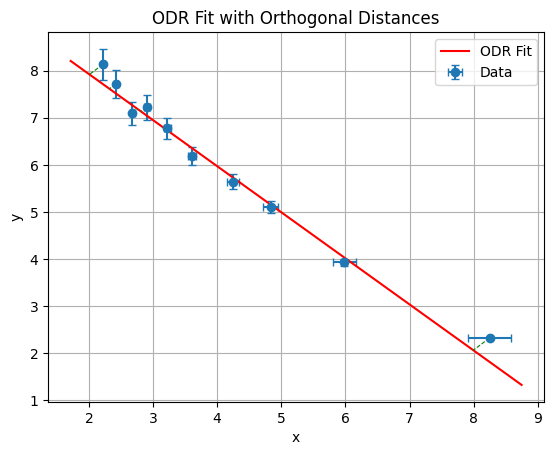

In [8]:
import matplotlib.pyplot as plt

# Plot data points with error bars
plt.errorbar(x, y, xerr=dx, yerr=dy, fmt='o', label='Data', capsize=3)

# Plot the best-fit line
x_fit = np.linspace(min(x) - 0.5, max(x) + 0.5, 500)
y_fit = m_hat * x_fit + q_hat
plt.plot(x_fit, y_fit, label='ODR Fit', color='red')

# Plot orthogonal distance segments
# These are calculated using the model's predicted points (closest point on the line)
for xi, yi in zip(x, y):
    # Find closest point (x_proj, y_proj) on the line to (xi, yi)
    # Using the formula for projection onto a line
    denom = m_hat**2 + 1
    x_proj = (xi + m_hat * (yi - q_hat)) / denom
    y_proj = (m_hat * xi + m_hat**2 * yi + q_hat) / denom
    plt.plot([xi, x_proj], [yi, y_proj], color='green', linestyle='--', linewidth=0.8)

plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.title('ODR Fit with Orthogonal Distances')
plt.show()


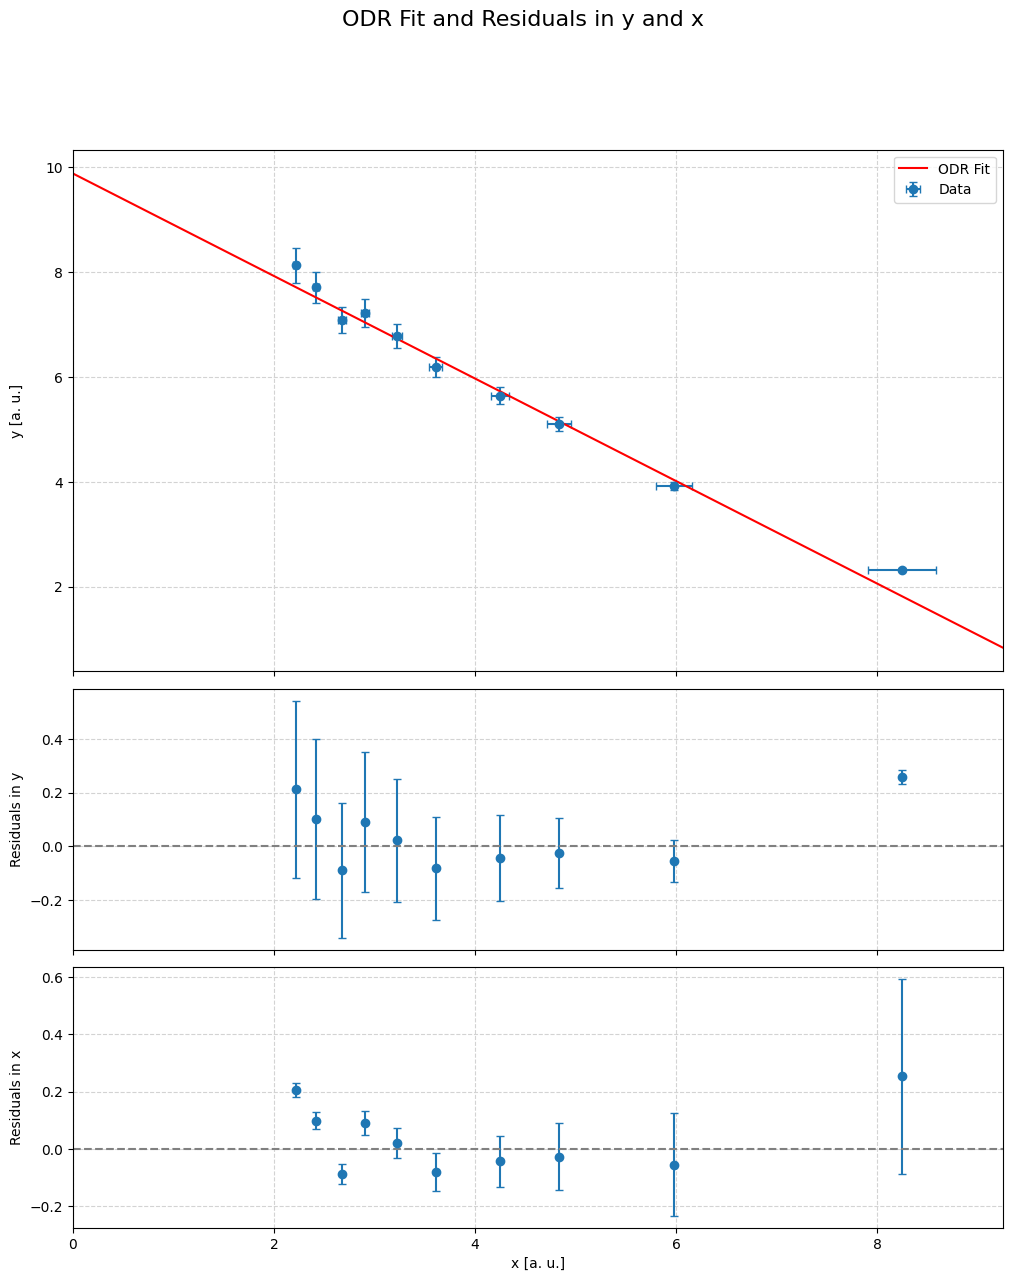

In [9]:
# Calcolo delle componenti ortogonali proiettate e dei residui
res_y = []
res_x = []

x_proj_list = []
y_proj_list = []

for xi, yi in zip(x, y):
    denom = m_hat**2 + 1
    x_proj = (xi + m_hat * (yi - q_hat)) / denom
    y_proj = (m_hat * xi + m_hat**2 * yi + q_hat) / denom
    res_y.append(yi - y_proj)
    res_x.append(xi - x_proj)
    x_proj_list.append(x_proj)
    y_proj_list.append(y_proj)

res_y = np.array(res_y)
res_x = np.array(res_x)

# Figura con 3 sottoplot
fig = plt.figure(figsize=(12, 14))
ax1, ax2, ax3 = fig.subplots(3, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1, 1], hspace=0.05))

x_lim = max(x) + 1
xgrid = np.linspace(0.0, x_lim, 100)

# Plot 1: dati con fit
ax1.errorbar(x, y, xerr=dx, yerr=dy, fmt='o', label='Data', capsize=3)
ax1.plot(xgrid, m_hat * xgrid + q_hat, label='ODR Fit', color='red')
ax1.set_ylabel('y [a. u.]')
ax1.grid(color='lightgray', ls='dashed')
ax1.legend()

# Plot 2: residui in y
ax2.errorbar(x, res_y, yerr=dy, fmt='o', capsize=3)
ax2.axhline(0.0, color='gray', linestyle='dashed')
ax2.set_ylabel('Residuals in y')
ax2.grid(color='lightgray', ls='dashed')

# Plot 3: residui in x, mostrati sull'asse y con errori dx
ax3.errorbar(x, res_x, yerr=dx, fmt='o', capsize=3)
ax3.axhline(0.0, color='gray', linestyle='dashed')
ax3.set_xlabel('x [a. u.]')
ax3.set_ylabel('Residuals in x')
ax3.grid(color='lightgray', ls='dashed')

plt.xlim(0.0, x_lim)
fig.align_ylabels((ax1, ax2, ax3))
plt.suptitle("ODR Fit and Residuals in y and x", fontsize=16)
plt.show()


### Least squares modified

this allows error on x

In [10]:
def fit_model(x, m, q):
    return m * x + q

In [11]:
x = np.array(x)
y= np.array(y)
sigma_x = np.array(dx)
sigma_y = np.array(dy)
fit_model=fit_model

In [12]:
# Run a first least-square fit ignoring the errors on x.
popt, pcov = curve_fit(fit_model, x, y, sigma=sigma_y)

# Iteratively update the errors and refit.
for i in range(3):
    sigma_eff = np.sqrt(sigma_y**2.0 + (popt[0] * sigma_x)**2.0)
    popt, pcov = curve_fit(fit_model, x, y, sigma=sigma_eff)
    chisq = (((y - fit_model(x, *popt)) / sigma_eff)**2.0).sum()
    
    # Print the fit output at each step.
    print(f'Step {i}...')
    print(popt, np.sqrt(pcov.diagonal()))
    print(f'Chisquare = {chisq:.2f}')


Step 0...
[-0.9631888   9.81976774] [0.04375748 0.19966969]
Chisquare = 7.31
Step 1...
[-0.97092652  9.85277659] [0.04469915 0.19821819]
Chisquare = 6.58
Step 2...
[-0.97139716  9.85476281] [0.04476226 0.19815346]
Chisquare = 6.54


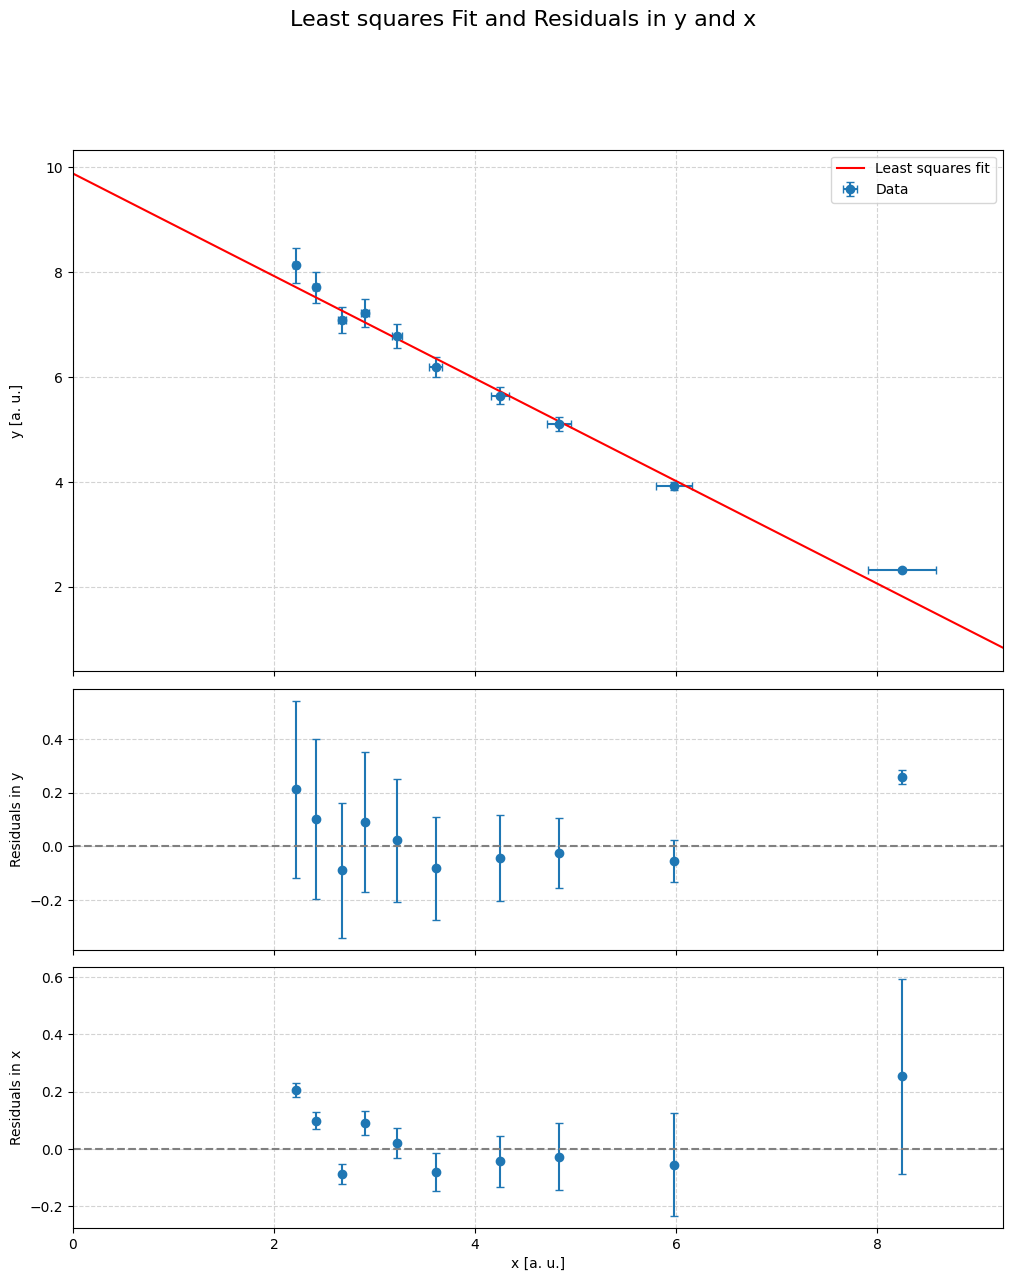

In [13]:
# Calcolo delle componenti ortogonali proiettate e dei residui  
# Is the graph equal to before?  

res_y = []
res_x = []

x_proj_list = []
y_proj_list = []

for xi, yi in zip(x, y):
    denom = m_hat**2 + 1
    x_proj = (xi + m_hat * (yi - q_hat)) / denom
    y_proj = (m_hat * xi + m_hat**2 * yi + q_hat) / denom
    res_y.append(yi - y_proj)
    res_x.append(xi - x_proj)
    x_proj_list.append(x_proj)
    y_proj_list.append(y_proj)

res_y = np.array(res_y)
res_x = np.array(res_x)

# Figura con 3 sottoplot
fig = plt.figure(figsize=(12, 14))
ax1, ax2, ax3 = fig.subplots(3, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1, 1], hspace=0.05))

x_lim = max(x) + 1
xgrid = np.linspace(0.0, x_lim, 100)

# Plot 1: dati con fit
ax1.errorbar(x, y, xerr=dx, yerr=dy, fmt='o', label='Data', capsize=3)
ax1.plot(xgrid, m_hat * xgrid + q_hat, label='Least squares fit', color='red')
ax1.set_ylabel('y [a. u.]')
ax1.grid(color='lightgray', ls='dashed')
ax1.legend()

# Plot 2: residui in y
ax2.errorbar(x, res_y, yerr=dy, fmt='o', capsize=3)
ax2.axhline(0.0, color='gray', linestyle='dashed')
ax2.set_ylabel('Residuals in y')
ax2.grid(color='lightgray', ls='dashed')

# Plot 3: residui in x, mostrati sull'asse y con errori dx
ax3.errorbar(x, res_x, yerr=dx, fmt='o', capsize=3)
ax3.axhline(0.0, color='gray', linestyle='dashed')
ax3.set_xlabel('x [a. u.]')
ax3.set_ylabel('Residuals in x')
ax3.grid(color='lightgray', ls='dashed')

plt.xlim(0.0, x_lim)
fig.align_ylabels((ax1, ax2, ax3))
plt.suptitle("Least squares Fit and Residuals in y and x", fontsize=16)
plt.show()